# Práctica EDA
Rubi Delgado Pérez

- Lectura del archivo, head, tail, sample, describe.  Validación de columnas numéricas para que funcione con todas.  
- Elementos mínimos:
    - Totales: 
        1. Total de videojuegos analizados,
        2. Total de géneros analizados,
        3. Plataformas analizadas

    - Ventas:
        1. Total de ventas por año,
        2. Juegos más vendidos por año,
        3. Plataformas con más ingresos por año. 
        Todos estos números desglosados por ingreso: NA, EU, JP, Otros y el Global,
        5. Gráfico de comparación de ventas entre géneros por año, 
        6. Insights: 2 Gráficos adicionales interesantes

- Revisar el EDA del ejercicio anterior y añadir siguientes elementos, basados en los últimos 4 años
    - Crecimiento:
        1. qué género ha tenido el mayor y menor crecimiento,
        2. qué plataforma ha tenido el mayor y menor crecimiento,
        3. qué videojuego ha tenido el mayor y menor crecimiento
    - 2 elementos adicionales que muestren oportunidades de mercado

In [3]:
# Importamos todas las librerías necesarias 
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# Leemos el archivo y lo cargamos en la variable df
df = pd.read_csv ('vgsales.csv') 

In [5]:
df.head (5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [6]:
df.tail (5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.0,0.0,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.0,0.0,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.0,0.0,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.0,0.0,0.01
16597,16600,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.0,0.0,0.01


In [7]:
df.sample (5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16061,16064,Digger Simulator,PC,2011.0,Simulation,Excalibur Publishing,0.00,0.01,0.00,0.00,0.01
3256,3258,Bolt,DS,2008.0,Adventure,Disney Interactive Studios,0.35,0.21,0.00,0.06,0.62
7627,7629,Shining Hearts,PSP,2010.0,Role-Playing,Sega,0.00,0.00,0.20,0.00,0.20
2358,2360,Peppa Pig: The Game,DS,2008.0,Misc,Pinnacle,0.00,0.82,0.00,0.06,0.88
262,263,Batman: Arkham Asylum,PS3,2009.0,Action,Eidos Interactive,2.23,1.34,0.07,0.61,4.25


In [9]:
# para ver los datos con sólo 2 decimales 
pd.options.display.float_format = '{:.2f}'.format

In [136]:
df.describe ()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.00,16598.00,16598.00,16598.00,16598.00,16598.00,16598.00
mean,8300.61,2006.42,0.26,0.15,0.08,0.05,0.54
std,4791.85,5.78,0.82,0.51,0.31,0.19,1.56
min,1.00,1980.00,0.00,0.00,0.00,0.00,0.01
25%,4151.25,2003.00,0.00,0.00,0.00,0.00,0.06
50%,8300.50,2007.00,0.08,0.02,0.00,0.01,0.17
75%,12449.75,2010.00,0.24,0.11,0.04,0.04,0.47
max,16600.00,2020.00,41.49,29.02,10.22,10.57,82.74


In [10]:
df.info ()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [11]:
df.shape

(16598, 11)

In [12]:
# El año está como decimales, lo cambiaré a enteros
df['Year'] = df ['Year'].astype ('Int64')
df.info ()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  Int64  
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: Int64(1), float64(5), int64(1), object(4)
memory usage: 1.4+ MB


In [13]:
# revisamos cuántos datos nulos y dónde están
df.isnull ().sum ()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [14]:
# Revisamos el % que representa esa cantidad de nulos en la información

# primero calculamos el total de datos que tenemos y el total de datos faltantes
total_cells = np.prod (df.shape)
missing_values_count = df.isnull().sum ()
total_missings = missing_values_count.sum ()

# luego calculamos el %
percent_missing = (total_missings / total_cells) * 100

print (f'Porcentaje de Datos que faltan: {percent_missing:.2f} %')

Porcentaje de Datos que faltan: 0.18 %


### Imputación de datos
- Revisamos el % de nulos y dado que es muy pequeño, los rellenaremos con la mediana y la moda

In [15]:
# Imputación de datos de las columnas faltantes: Year y Publisher
df['Year'] = df['Year'].fillna(df['Year'].median())
df['Publisher'] = df['Publisher'].fillna(df['Publisher'].mode()[0])

df.sample (5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
15616,15619,Nodame Cantabile: Tanoshii Ongaku no Jikan Desu,DS,2010,Misc,Namco Bandai Games,0.00,0.00,0.02,0.00,0.02
16239,16242,Builder's Block,PS,1999,Strategy,EON Digital Entertainment,0.01,0.00,0.00,0.00,0.01
12708,12710,G1 Jockey 2,PS2,2000,Sports,Tecmo Koei,0.00,0.00,0.06,0.00,0.06
11232,11234,Sega Bass Fishing,DC,1999,Sports,Sega,0.00,0.00,0.09,0.00,0.09
2432,2434,Madden NFL 09 All-Play,Wii,2008,Sports,Electronic Arts,0.78,0.01,0.00,0.07,0.85


In [16]:
# confirmamos que ya no nulos
df.isnull ().sum ()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

### EDA
Totales:
1)	Total de videojuegos analizados,
2)	Total de géneros analizados,
3)	Plataformas analizadas

In [17]:
# 1. Total de videojuegos analizados
print (f'El total de videojuegos analizados es de {df['Name'].nunique ():,}')

El total de videojuegos analizados es de 11,493


In [18]:
# 2. Total de géneros analizados
print (f'El total de géneros analizados es de {df['Genre'].nunique ():,}')

El total de géneros analizados es de 12


In [19]:
# 3. Total de plataformas analizadas
print (f'El total de plataformas analizadas es de {df['Platform'].nunique ():,}')

El total de plataformas analizadas es de 31


In [20]:
df.nunique ()

Rank            16598
Name            11493
Platform           31
Year               39
Genre              12
Publisher         578
NA_Sales          409
EU_Sales          305
JP_Sales          244
Other_Sales       157
Global_Sales      623
dtype: int64

In [21]:
df.head (5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


###
Ventas:
1.	Total de ventas por año,
2.	Juegos más vendidos por año,
3.	Plataformas con más ingresos por año. 
Todos estos números desglosados por ingreso: NA, EU, JP, Otros y el Global,
5.	Gráfico de comparación de ventas entre géneros por año, 
6.	Insights: 2 Gráficos adicionales interesantes


<Axes: xlabel='Year'>

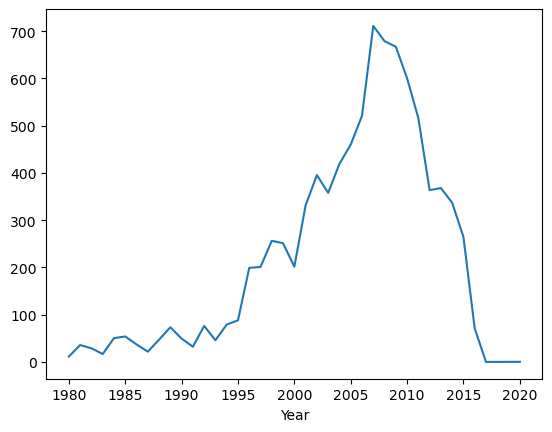

In [ ]:
# 1. Total de ventas por año: lo graficaremos para mejor visualización
df.groupby ('Year')['Global_Sales'].sum().plot.line ()

In [35]:
# En caso de que se requiera ver las ventas anuales por región
df.groupby('Year')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Global_Sales']].sum().sort_index()

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Year,,,,,
1980,10.59,0.67,0.00,0.12,11.38
1981,33.40,1.96,0.00,0.32,35.77
1982,26.92,1.65,0.00,0.31,28.86
1983,7.76,0.80,8.10,0.14,16.79
1984,33.28,2.10,14.27,0.70,50.36
1985,33.73,4.74,14.56,0.92,53.94
1986,12.50,2.84,19.81,1.93,37.07
1987,8.46,1.41,11.63,0.20,21.74
1988,23.87,6.59,15.76,0.99,47.22


In [39]:
# 2. Juegos más vendidos por año y por región
game_topyear = pd.DataFrame({
    'NA': df.loc[df.groupby('Year')['NA_Sales'].idxmax()].set_index('Year')['Name'],
    'EU': df.loc[df.groupby('Year')['EU_Sales'].idxmax()].set_index('Year')['Name'],
    'JP': df.loc[df.groupby('Year')['JP_Sales'].idxmax()].set_index('Year')['Name'],
    'Other': df.loc[df.groupby('Year')['Other_Sales'].idxmax()].set_index('Year')['Name'],
    'Global': df.loc[df.groupby('Year')['Global_Sales'].idxmax()].set_index('Year')['Name']
})

game_topyear

,NA,EU,JP,Other,Global
Year,,,,,
1980,Asteroids,Asteroids,Asteroids,Asteroids,Asteroids
1981,Pitfall!,Pitfall!,Pitfall!,Pitfall!,Pitfall!
1982,Pac-Man,Pac-Man,Pac-Man,Pac-Man,Pac-Man
1983,Pitfall II: Lost Caverns,Mario Bros.,Baseball,Baseball,Baseball
1984,Duck Hunt,Duck Hunt,Golf,Duck Hunt,Duck Hunt
1985,Super Mario Bros.,Super Mario Bros.,Super Mario Bros.,Super Mario Bros.,Super Mario Bros.
1986,The Legend of Zelda,The Legend of Zelda,Super Mario Bros.: The Lost Levels,Dragon Warrior,The Legend of Zelda
1987,Zelda II: The Adventure of Link,Zelda II: The Adventure of Link,Dragon Warrior II,Zelda II: The Adventure of Link,Zelda II: The Adventure of Link
1988,Super Mario Bros. 3,Super Mario Bros. 3,Super Mario Bros. 3,Super Mario Bros. 3,Super Mario Bros. 3


In [42]:
# 3. Plataformas con más ingresos por año y por región
platform_topyear = pd.DataFrame({
    'NA': df.loc[df.groupby('Year')['NA_Sales'].idxmax()].set_index('Year')['Platform'],
    'EU': df.loc[df.groupby('Year')['EU_Sales'].idxmax()].set_index('Year')['Platform'],
    'JP': df.loc[df.groupby('Year')['JP_Sales'].idxmax()].set_index('Year')['Platform'],
    'Other': df.loc[df.groupby('Year')['Other_Sales'].idxmax()].set_index('Year')['Platform'],
    'Global': df.loc[df.groupby('Year')['Global_Sales'].idxmax()].set_index('Year')['Platform']
})

platform_topyear

,NA,EU,JP,Other,Global
Year,,,,,
1980,2600,2600,2600,2600,2600
1981,2600,2600,2600,2600,2600
1982,2600,2600,2600,2600,2600
1983,2600,NES,NES,NES,NES
1984,NES,NES,NES,NES,NES
1985,NES,NES,NES,NES,NES
1986,NES,NES,NES,NES,NES
1987,NES,NES,NES,NES,NES
1988,NES,NES,NES,NES,NES


<Axes: xlabel='Year'>

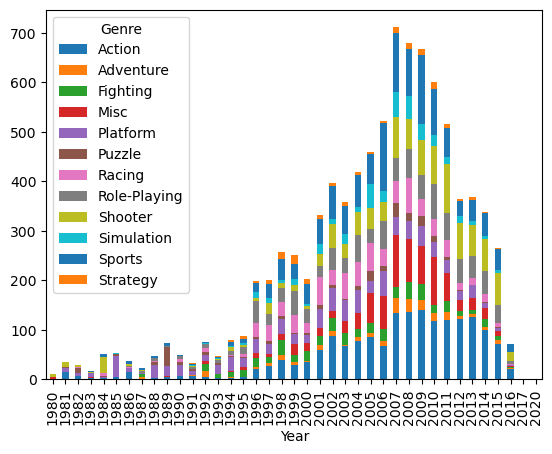

In [43]:
# 4. Gráfico de comparación de ventas entre géneros por año 
pd.crosstab (df ['Year'], df['Genre'], values= df['Global_Sales'], aggfunc= 'sum').plot.bar (stacked= True)

In [45]:
df.sample (5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
11634,11636,Emily the Strange: Strangerous,DS,2011,Action,DTP Entertainment,0.04,0.03,0.00,0.01,0.08
8287,8289,MX World Tour Featuring Jamie Little,PS2,2005,Racing,Play It,0.08,0.07,0.00,0.02,0.17
1009,1011,Disney's Aladdin,SNES,1993,Platform,Capcom,0.94,0.34,0.21,0.27,1.75
1379,1381,Call of Duty: Black Ops,Wii,2010,Shooter,Activision,0.82,0.47,0.00,0.12,1.40
12305,12307,Nicola Kanshuu: Model * Oshare Audition,DS,2010,Misc,Alchemist,0.00,0.00,0.06,0.00,0.06


<Axes: xlabel='Year'>

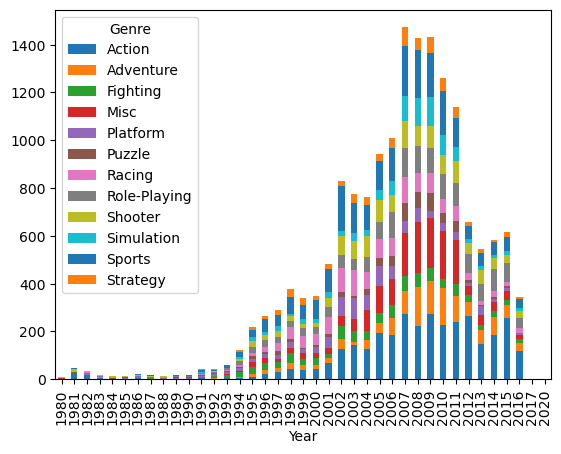

In [137]:
# 5. Insights: 2 Gráficos adicionales interesantes

# Gráfico de cantidad de Videojuegos por Género a lo largo de los años
pd.crosstab (df ['Year'], df['Genre'], values= df['Name'], aggfunc= 'count').plot.bar (stacked= True)

# La gráfica muestra que los géneros de los videojuegos que por lo general han existido todos los años son Action, Misc, Racing y Sports

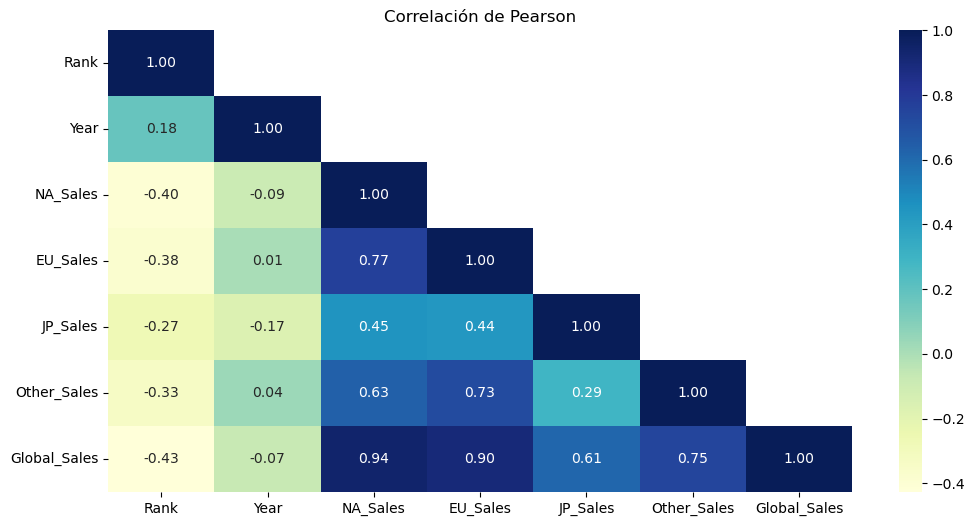

In [133]:
# Grafico de correlación de variables

plt.figure (figsize= (12,6))  # tamaño de la gráfica
plt.title('Correlación de Pearson')
corr_df = df.corr (numeric_only= True, method= 'pearson')   # generamos la matriz de correlación
df_lt = corr_df.where (np.tril (np.ones (corr_df.shape)).astype (bool))  # mostramos sólo un triángulo de la tabla, no valores/relaciones repetidas
hmap = sns.heatmap (df_lt, cmap= 'YlGnBu', annot= True, fmt= '.2f')  # generamos la gráfica con la información, colores y decimales deseados

# Vemos una correlación fuerte entre las ventas de Videojuegos en Europa con las de Norte América (0.77)

#### Crecimientos basados en los últimos 4 años
1)	qué género ha tenido el mayor y menor crecimiento,
2)	qué plataforma ha tenido el mayor y menor crecimiento,
3)	qué videojuego ha tenido el mayor y menor crecimiento,
4)  2 elementos adicionales que muestren oportunidades de mercado

In [81]:
# De inicio, generamos el df de los útlimos 4 años

# buscamos el último año disponible
last_year = df['Year'].max()

# generamos el df con los últimos 4 años
df_last4y = df[df['Year'] >= last_year - 3]

df_last4y.tail(5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
5957,5959,Imagine: Makeup Artist,DS,2020,Simulation,Ubisoft,0.27,0.00,0.00,0.02,0.29
14390,14393,Phantasy Star Online 2 Episode 4: Deluxe Package,PS4,2017,Role-Playing,Sega,0.00,0.00,0.03,0.00,0.03
16241,16244,Phantasy Star Online 2 Episode 4: Deluxe Package,PSV,2017,Role-Playing,Sega,0.00,0.00,0.01,0.00,0.01
16438,16441,Brothers Conflict: Precious Baby,PSV,2017,Action,Idea Factory,0.00,0.00,0.01,0.00,0.01


In [80]:
df_last4y.shape

(4, 11)

### NOTA: Corrección
- En los últimos 4 años (del 2017 al 2020) sólo hay 4 registros
- Según la gráfica de las ventas globales, el punto máximo de ventas fue en 2006 y a partir de ahí empezó a decaer la venta de manera general
- Por lo tanto si queremos ver un crecimiento en ventas lo haremos considerando el periodo del 2000 al 2007.  

In [88]:
# generamos el df con los datos del 2000-2007
df_20002007 = df[(df['Year'] >= 2000) & (df['Year'] <= 2007)]

df_20002007.sample(5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16242,16245,F.E.A.R. Perseus Mandate,PC,2007,Shooter,Vivendi Games,0.01,0.00,0.00,0.00,0.01
3083,3085,Suikoden IV,PS2,2004,Role-Playing,Konami Digital Entertainment,0.17,0.13,0.30,0.05,0.66
2653,2655,James Bond 007: Nightfire,GC,2002,Shooter,Electronic Arts,0.60,0.16,0.00,0.02,0.78
2930,2932,NCAA Football 2001,PS,2000,Sports,Electronic Arts,0.39,0.26,0.00,0.05,0.70
164,165,Super Mario World,GBA,2001,Platform,Nintendo,3.21,1.11,0.95,0.20,5.46


In [89]:
df_20002007.shape

(6620, 11)

In [90]:
# 1. Género con mayor y menor crecimiento

# primero generamos la tabla pivote para las ventas globales por género
df_sales_genre = pd.pivot_table (df_20002007, values= 'Global_Sales', index= 'Year', columns= 'Genre', aggfunc= 'sum').fillna (0).reset_index ()
df_sales_genre.tail (5)


Genre,Year,Action,Adventure,Fighting,Misc,Platform,Puzzle,Racing,Role-Playing,Shooter,Simulation,Sports,Strategy
3,2003,67.93,2.14,23.73,23.82,42.89,2.42,52.19,30.28,27.14,21.21,56.11,7.99
4,2004,76.26,8.70,16.78,31.32,47.34,8.43,47.86,53.95,46.95,10.85,63.68,7.19
5,2005,85.69,8.53,19.72,61.24,23.56,20.45,56.42,28.55,41.60,49.27,59.54,5.37
6,2006,66.58,11.47,22.55,67.35,49.80,10.90,34.09,57.73,38.37,21.77,136.16,4.27
7,2007,134.80,28.71,22.47,104.61,37.81,26.73,44.44,47.42,82.21,51.01,119.89,11.11


In [91]:
# ahora calculamos la variación porcentual de la venta de género respecto al año anterior, usamos el comando pct_change 
dfsales_genre_pct = df_sales_genre [list (df_sales_genre.columns)[1:13]].pct_change ()
dfsales_genre_pct

Genre,Action,Adventure,Fighting,Misc,Platform,Puzzle,Racing,Role-Playing,Shooter,Simulation,Sports,Strategy
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.74,2.06,-0.10,0.06,1.45,1.09,1.79,-0.24,2.64,4.78,0.25,-0.11
2,0.46,0.21,0.38,-0.04,0.17,-0.33,-0.46,1.05,0.96,-0.45,0.27,-0.26
3,-0.22,-0.81,-0.05,0.52,-0.07,-0.55,0.73,-0.33,-0.44,0.96,-0.14,0.44
4,0.12,3.07,-0.29,0.31,0.10,2.48,-0.08,0.78,0.73,-0.49,0.13,-0.10
5,0.12,-0.02,0.18,0.96,-0.50,1.43,0.18,-0.47,-0.11,3.54,-0.07,-0.25
6,-0.22,0.34,0.14,0.10,1.11,-0.47,-0.40,1.02,-0.08,-0.56,1.29,-0.20
7,1.02,1.50,-0.00,0.55,-0.24,1.45,0.30,-0.18,1.14,1.34,-0.12,1.60


In [92]:
# dado que encontramos varios 0 en las ventas de algunos géneros, se generan datos infinitos (división entre 0). Ajustamos esos datos

dfsales_genre_pct = (df_sales_genre.iloc[:, 1:13].pct_change().replace([np.inf, -np.inf], np.nan))
dfsales_genre_pct

Genre,Action,Adventure,Fighting,Misc,Platform,Puzzle,Racing,Role-Playing,Shooter,Simulation,Sports,Strategy
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.74,2.06,-0.10,0.06,1.45,1.09,1.79,-0.24,2.64,4.78,0.25,-0.11
2,0.46,0.21,0.38,-0.04,0.17,-0.33,-0.46,1.05,0.96,-0.45,0.27,-0.26
3,-0.22,-0.81,-0.05,0.52,-0.07,-0.55,0.73,-0.33,-0.44,0.96,-0.14,0.44
4,0.12,3.07,-0.29,0.31,0.10,2.48,-0.08,0.78,0.73,-0.49,0.13,-0.10
5,0.12,-0.02,0.18,0.96,-0.50,1.43,0.18,-0.47,-0.11,3.54,-0.07,-0.25
6,-0.22,0.34,0.14,0.10,1.11,-0.47,-0.40,1.02,-0.08,-0.56,1.29,-0.20
7,1.02,1.50,-0.00,0.55,-0.24,1.45,0.30,-0.18,1.14,1.34,-0.12,1.60


In [93]:
# finalmente obtenermos el género con mayor y menor crecimiento
dfsales_genre_pct.mean ().sort_values (ascending= False)

Genre
Simulation     1.30
Adventure      0.91
Puzzle         0.73
Shooter        0.69
Misc           0.35
Racing         0.29
Action         0.29
Platform       0.29
Role-Playing   0.23
Sports         0.23
Strategy       0.16
Fighting       0.04
dtype: float64

In [94]:
print ('El género con mayor crecimiento de ventas ha sido:')
dfsales_genre_pct.mean ().sort_values (ascending= False).head (1)

El género con mayor crecimiento de ventas ha sido:


Genre
Simulation   1.30
dtype: float64

In [95]:
print ('El género con menor crecimiento de ventas ha sido:')
dfsales_genre_pct.mean ().sort_values (ascending= True).head (1)

El género con menor crecimiento de ventas ha sido:


Genre
Fighting   0.04
dtype: float64

In [96]:
# 2. Plataforma ha tenido el mayor y menor crecimiento

# primero generamos la tabla pivote para las ventas globales por plataforma
df_sales_plat = pd.pivot_table (df_20002007, values= 'Global_Sales', index= 'Year', columns= 'Platform', aggfunc= 'sum').fillna (0).reset_index ()
df_sales_plat.tail (5)

Platform,Year,2600,3DS,DC,DS,GB,GBA,GC,N64,PC,PS,PS2,PS3,PSP,PSV,WS,Wii,X360,XB
3,2003,0.00,0.00,0.00,0.00,0.00,56.73,50.66,0.00,8.96,2.05,184.29,0.00,0.00,0.00,0.00,0.00,0.00,55.16
4,2004,0.00,0.00,0.00,17.46,0.00,78.09,28.89,0.00,10.46,0.00,211.78,0.00,7.13,0.00,0.00,0.00,0.00,65.50
5,2005,0.00,0.00,0.00,131.40,0.00,33.90,27.80,0.00,4.47,0.00,160.65,0.00,44.23,0.00,0.00,0.00,8.32,49.17
6,2006,0.00,0.00,0.00,121.15,0.00,5.35,11.29,0.00,2.97,0.00,103.42,21.07,55.85,0.00,0.00,137.91,51.88,10.15
7,2007,10.51,1.18,0.02,152.89,1.03,8.37,2.49,0.67,13.17,3.27,98.18,82.30,52.05,0.30,0.00,171.87,106.19,6.72


In [97]:
# ahora calculamos la variación porcentual de la venta de plataformas respecto al año anterior, 
# usamos pct_canche y replace para evitar los valores infinitos
dfsales_plat_pct = (df_sales_plat.iloc[:, 1:32].pct_change().replace([np.inf, -np.inf], np.nan))
dfsales_plat_pct

Platform,2600,3DS,DC,DS,GB,GBA,GC,N64,PC,PS,PS2,PS3,PSP,PSV,WS,Wii,X360,XB
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,-0.82,NaN,-0.53,1026.00,NaN,-0.90,0.18,-0.63,3.26,NaN,NaN,NaN,-0.59,NaN,NaN,21.46
2,NaN,NaN,-0.73,NaN,-1.00,0.21,0.97,-0.98,0.56,-0.81,0.23,NaN,NaN,NaN,-1.00,NaN,NaN,1.17
3,NaN,NaN,-1.00,NaN,NaN,-0.24,-0.02,-1.00,0.04,-0.69,-0.10,NaN,NaN,NaN,NaN,NaN,NaN,0.15
4,NaN,NaN,NaN,NaN,NaN,0.38,-0.43,NaN,0.17,-1.00,0.15,NaN,NaN,NaN,NaN,NaN,NaN,0.19
5,NaN,NaN,NaN,6.53,NaN,-0.57,-0.04,NaN,-0.57,NaN,-0.24,NaN,5.20,NaN,NaN,NaN,NaN,-0.25
6,NaN,NaN,NaN,-0.08,NaN,-0.84,-0.59,NaN,-0.34,NaN,-0.36,NaN,0.26,NaN,NaN,NaN,5.24,-0.79
7,NaN,NaN,NaN,0.26,NaN,0.56,-0.78,NaN,3.43,NaN,-0.05,2.91,-0.07,NaN,NaN,0.25,1.05,-0.34


In [98]:
# finalmente obtenermos la plataforma con mayor y menor crecimiento
dfsales_plat_pct.mean ().sort_values (ascending= False)

Platform
GBA    146.50
X360     3.14
XB       3.08
PS3      2.91
DS       2.24
PSP      1.80
PC       0.50
PS2      0.41
Wii      0.25
GC      -0.15
GB      -0.77
PS      -0.78
WS      -0.79
DC      -0.85
N64     -0.96
2600      NaN
3DS       NaN
PSV       NaN
dtype: float64

In [99]:
print ('La plataforma con mayor crecimiento de ventas ha sido:')
dfsales_plat_pct.mean ().sort_values (ascending= False).head (1)

La plataforma con mayor crecimiento de ventas ha sido:


Platform
GBA   146.50
dtype: float64

In [100]:
print ('La plataforma con menor crecimiento de ventas ha sido:')
dfsales_plat_pct.mean ().sort_values (ascending= True).head (1)

La plataforma con menor crecimiento de ventas ha sido:


Platform
N64   -0.96
dtype: float64

In [101]:
# 3. Videojuego ha tenido el mayor y menor crecimiento

# primero generamos la tabla pivote para las ventas globales por videojuego
df_sales_game = pd.pivot_table (df_20002007, values= 'Global_Sales', index= 'Year', columns= 'Name', aggfunc= 'sum').fillna (0).reset_index ()

# luego calculamos la variación porcentual de la venta de videojuegos respecto al año anterior, usamos pct_canche y replace para evitar infinitos
dfsales_game_pct = (df_sales_game.iloc[:, 1:11494].pct_change().replace([np.inf, -np.inf], np.nan))

# finalmente obtenemos el videojuego con mayor y menor crecimiento
print ('El videojuego con mayor crecimiento de ventas ha sido:')
dfsales_game_pct.mean ().sort_values (ascending= False).head (1)

El videojuego con mayor crecimiento de ventas ha sido:


Name
Deal or No Deal   170.00
dtype: float64

In [102]:
print ('El videojuego con menor crecimiento de ventas ha sido:')
dfsales_game_pct.mean ().sort_values (ascending= True).head (1)

El videojuego con menor crecimiento de ventas ha sido:


Name
.hack//G.U. Vol.1//Rebirth   -1.00
dtype: float64

In [103]:
df.sample (5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
3507,3509,Spider-Man 3,X360,2007,Platform,Activision,0.49,0.04,0.00,0.04,0.57
14476,14479,Klonoa 2: Dream Champ Tournament,GBA,2002,Platform,Namco Bandai Games,0.02,0.01,0.00,0.00,0.03
7656,7658,The Cheetah Girls: Passport to Stardom,DS,2008,Misc,Disney Interactive Studios,0.18,0.00,0.00,0.01,0.20
12058,12060,Dynasty Warriors 8: Empires,XOne,2014,Action,Tecmo Koei,0.04,0.02,0.00,0.01,0.07
632,633,Halo: Combat Evolved Anniversary,X360,2011,Shooter,Microsoft Game Studios,1.44,0.73,0.04,0.22,2.44


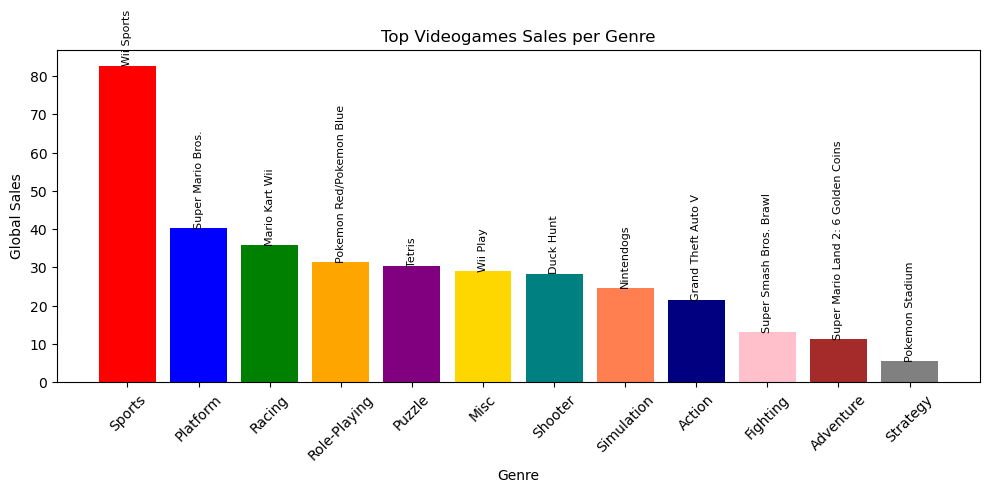

In [131]:
# 4. Dos elementos adicionales que muestren oportunidades de mercado

# a) Videojuego de cada género que ha tenido más venta

top_game_genre = df.loc[df.groupby('Genre')['Global_Sales'].idxmax(),['Genre', 'Name', 'Global_Sales']].sort_values('Global_Sales',ascending=False)
plt.figure(figsize=(10, 5))
colores = ['red', 'blue', 'green', 'orange', 'purple', 'gold', 'teal', 'coral', 'navy', 'pink', 'brown', 'gray']
barras = plt.bar(top_game_genre['Genre'], top_game_genre['Global_Sales'], color= colores)
# agregamos el nombre del videojuego sobre cada barra
for barra, juego in zip(barras, top_game_genre['Name']):
    plt.text (barra.get_x() + barra.get_width()/2, barra.get_height(), juego, ha='center', va='bottom', fontsize=8, rotation= 90)
plt.title('Top Videogames Sales per Genre')
plt.xlabel('Genre')
plt.ylabel('Global Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [132]:
top_game_genre

,Genre,Name,Global_Sales
0,Sports,Wii Sports,82.74
1,Platform,Super Mario Bros.,40.24
2,Racing,Mario Kart Wii,35.82
4,Role-Playing,Pokemon Red/Pokemon Blue,31.37
5,Puzzle,Tetris,30.26
7,Misc,Wii Play,29.02
9,Shooter,Duck Hunt,28.31
10,Simulation,Nintendogs,24.76
16,Action,Grand Theft Auto V,21.40
39,Fighting,Super Smash Bros. Brawl,13.04


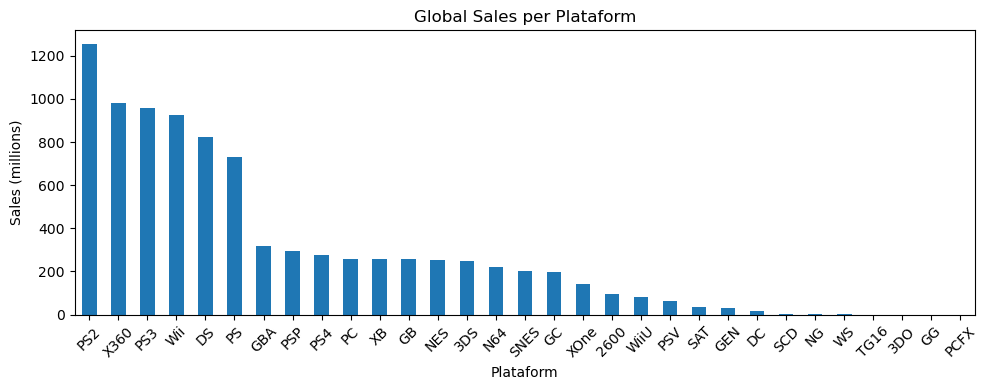

In [135]:
# b) Gráfico de Ventas globales por plataforma
sales_plataform = (df.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False))

plt.figure(figsize=(10,4))
sales_plataform.plot(kind='bar')
plt.title('Global Sales per Plataform')
plt.xlabel('Plataform')
plt.ylabel('Sales (millions)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Las 6 plataformas con mayores ventas totales son PPS2, X360, PS3, Wii, DS y PS